# 02 · Feature Engineering
**Notebook 2 of 4** · run order: 01 → 02 → 03 → 04

> Synthetic demonstration data. See notebook 01 for what that means.

**What this notebook does**
1. Choose who we model and which months we may look at
2. Turn monthly rows into one row of features per customer
3. Check the features for problems (missing values, leakage)
4. Split into train / validation / test, **stratified** so every type of customer is represented

**Reads:** `data/panel_monthly.parquet`, `work/labels.parquet`, `work/clean_customers.parquet`
**Saves:** `work/train.parquet`, `work/valid.parquet`, `work/test.parquet`, `work/figures/feature_vs_label.png`

## 0 · Setup

**Where to run it**
- **Your computer:** keep the folder layout as delivered (`data/` next to the notebooks). Nothing to change.
- **Google Colab:** upload the two parquet files, set `DATA_DIR = "/content"` and `WORK_DIR = "/content/work"`.
- **Kaggle:** add the parquet files as a dataset, set `DATA_DIR = "/kaggle/input/<your-dataset-name>"` and `WORK_DIR = "/kaggle/working"`.

In [1]:
# ---- Settings: change these two lines if you run on Colab or Kaggle ----
DATA_DIR = "data"   # folder that holds panel_monthly.parquet and customers.parquet
WORK_DIR = "work"   # folder where the notebooks save their results for the next notebook

In [2]:
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")

FIG_DIR = os.path.join(WORK_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)
LABEL = "value_compressed_flag"

for name in ["labels.parquet", "clean_customers.parquet"]:
    if not os.path.exists(os.path.join(WORK_DIR, name)):
        print("Missing", name, "- please run notebook 01 first.")

In [3]:
panel = pd.read_parquet(os.path.join(DATA_DIR, "panel_monthly.parquet"))
labels = pd.read_parquet(os.path.join(WORK_DIR, "labels.parquet"))
customers = pd.read_parquet(os.path.join(WORK_DIR, "clean_customers.parquet"))
print("panel:", panel.shape, "| labels:", labels.shape, "| customers:", customers.shape)

panel: (2352248, 8) | labels: (200000, 5) | customers: (200000, 6)


## 1 · Who do we model, and which months may we use?
- **Who:** active customers only (they have not left, so we can still act on them).
- **Which months:** only **months 1–9**. The label looks at the last three months (10–12), so features must come from *before* that. Using later months would be cheating.

```
Month:    1  2  3  4  5  6  7  8  9 | 10  11  12
          [------ features -------]   [ label window ]
```

In [4]:
active_ids = labels[labels["churned_flag"] == 0].index
observed = panel[(panel["month"] <= 9) & (panel["customer_id"].isin(active_ids))]

print("Active customers:", len(active_ids))
print("Rows used for features:", len(observed))
print("Months used:", sorted(observed["month"].unique().tolist()))

Active customers: 175571
Rows used for features: 1580139
Months used: [1, 2, 3, 4, 5, 6, 7, 8, 9]


## 2 · Build the features
For each of the four behaviour columns we compute, per customer:

| Feature | Meaning |
|---|---|
| `_mean` | average over months 1–9 |
| `_first3` | average over months 1–3 (the customer's early normal) |
| `_last3` | average over months 7–9 (most recent behaviour) |
| `_max` | worst single month |
| `_change` | `_last3` minus `_first3` (is it getting worse?) |

The `_change` features are a simple **trend over time**. Revenue is not used.

In [5]:
behaviours = ["monthly_overage_fee", "data_overage_fee",
              "dropped_blocked_calls", "customer_service_calls"]

average = observed.groupby("customer_id")[behaviours].mean().add_suffix("_mean")
first3 = observed[observed["month"] <= 3].groupby("customer_id")[behaviours].mean().add_suffix("_first3")
last3 = observed[observed["month"] >= 7].groupby("customer_id")[behaviours].mean().add_suffix("_last3")
worst = observed.groupby("customer_id")[behaviours].max().add_suffix("_max")

features = pd.concat([average, first3, last3, worst], axis=1)
features.head()

,monthly_overage_fee_mean,data_overage_fee_mean,dropped_blocked_calls_mean,customer_service_calls_mean,monthly_overage_fee_first3,data_overage_fee_first3,dropped_blocked_calls_first3,customer_service_calls_first3,monthly_overage_fee_last3,data_overage_fee_last3,dropped_blocked_calls_last3,customer_service_calls_last3,monthly_overage_fee_max,data_overage_fee_max,dropped_blocked_calls_max,customer_service_calls_max
customer_id,,,,,,,,,,,,,,,,
1,13.748890,0.986667,1.666667,0.555556,11.193334,0.000000,3.000000,0.000000,17.593332,0.000000,0.333333,1.000000,37.380001,8.880000,6,2
2,5.622222,0.618889,2.000000,0.666667,4.600000,0.523333,1.333333,0.666667,8.956666,0.770000,2.000000,1.000000,13.580000,2.310000,3,2
3,3.412222,0.318889,5.333333,1.111111,3.546667,0.400000,5.333333,1.666667,3.713333,0.350000,5.000000,0.333333,6.070000,1.050000,8,3
4,4.408889,0.516667,0.444444,0.333333,3.053333,0.480000,0.000000,0.666667,6.023333,0.643333,0.666667,0.333333,10.210000,1.930000,2,1
5,47.655556,9.295555,3.000000,0.222222,47.713333,3.500000,4.000000,0.333333,35.703335,17.910000,3.000000,0.000000,77.889999,19.719999,6,1


In [6]:
for column in behaviours:
    features[column + "_change"] = features[column + "_last3"] - features[column + "_first3"]

print("Behaviour features so far:", features.shape[1])

Behaviour features so far: 20


### Add facts that do not change over time

In [7]:
# tenure at month 9
features["tenure_months"] = observed[observed["month"] == 9].set_index("customer_id")["account_tenure_months"]

# income and the missing-income flag
facts = customers.set_index("customer_id")[["estimated_income_bracket", "income_missing"]]
features = features.join(facts)

print("Total features:", features.shape[1])
list(features.columns)

Total features: 23


['monthly_overage_fee_mean',
 'data_overage_fee_mean',
 'dropped_blocked_calls_mean',
 'customer_service_calls_mean',
 'monthly_overage_fee_first3',
 'data_overage_fee_first3',
 'dropped_blocked_calls_first3',
 'customer_service_calls_first3',
 'monthly_overage_fee_last3',
 'data_overage_fee_last3',
 'dropped_blocked_calls_last3',
 'customer_service_calls_last3',
 'monthly_overage_fee_max',
 'data_overage_fee_max',
 'dropped_blocked_calls_max',
 'customer_service_calls_max',
 'monthly_overage_fee_change',
 'data_overage_fee_change',
 'dropped_blocked_calls_change',
 'customer_service_calls_change',
 'tenure_months',
 'estimated_income_bracket',
 'income_missing']

### Attach the label

In [8]:
data = features.join(labels[LABEL])
print("Modelling table:", data.shape)
print("Compressed share:", round(data[LABEL].mean() * 100, 1), "%")
data.head()

Modelling table: (175571, 24)
Compressed share: 11.4 %


,monthly_overage_fee_mean,data_overage_fee_mean,dropped_blocked_calls_mean,customer_service_calls_mean,monthly_overage_fee_first3,data_overage_fee_first3,dropped_blocked_calls_first3,customer_service_calls_first3,monthly_overage_fee_last3,data_overage_fee_last3,...,dropped_blocked_calls_max,customer_service_calls_max,monthly_overage_fee_change,data_overage_fee_change,dropped_blocked_calls_change,customer_service_calls_change,tenure_months,estimated_income_bracket,income_missing,value_compressed_flag
customer_id,,,,,,,,,,,,,,,,,,,,,
1,13.748890,0.986667,1.666667,0.555556,11.193334,0.000000,3.000000,0.000000,17.593332,0.000000,...,6,2,6.399999,0.000000,-2.666667,1.000000,15,-1.0,1,0
2,5.622222,0.618889,2.000000,0.666667,4.600000,0.523333,1.333333,0.666667,8.956666,0.770000,...,3,2,4.356666,0.246667,0.666667,0.333333,63,-1.0,1,0
3,3.412222,0.318889,5.333333,1.111111,3.546667,0.400000,5.333333,1.666667,3.713333,0.350000,...,8,3,0.166667,-0.050000,-0.333333,-1.333333,55,3.0,0,0
4,4.408889,0.516667,0.444444,0.333333,3.053333,0.480000,0.000000,0.666667,6.023333,0.643333,...,2,1,2.970000,0.163333,0.666667,-0.333333,40,2.0,0,0
5,47.655556,9.295555,3.000000,0.222222,47.713333,3.500000,4.000000,0.333333,35.703335,17.910000,...,6,1,-12.009998,14.410000,-1.000000,-0.333333,39,5.0,0,0


## 3 · Quality checks

In [9]:
print("Missing values:", data.isna().sum().sum())
print("Duplicate customers:", data.index.duplicated().sum())

forbidden = [c for c in features.columns
             if "revenue" in c or "latent" in c or "churn" in c or "segment" in c]
print("Columns that must NOT be features (revenue, answer key, churn, segment):", forbidden)

Missing values: 0
Duplicate customers: 0
Columns that must NOT be features (revenue, answer key, churn, segment): []


### Which features move with the label?
A quick look before modelling. Correlation only shows a straight-line link; the model can find more.

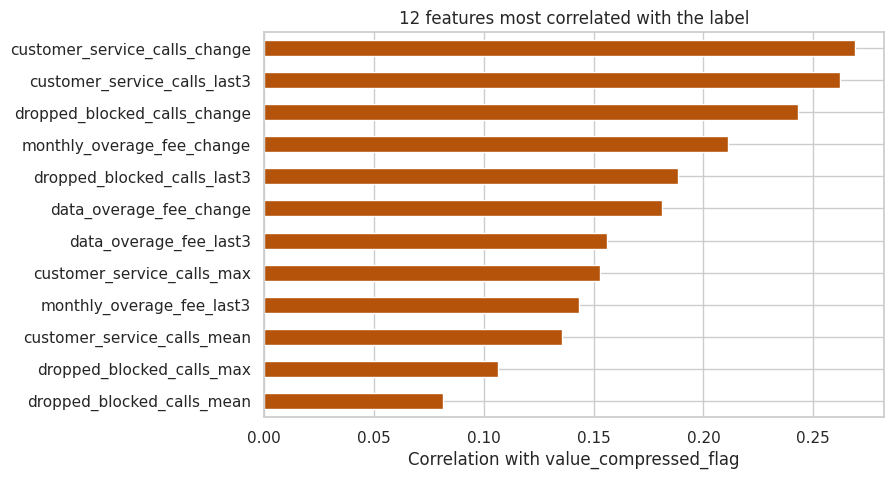

In [10]:
corr = data.corr()[LABEL].drop(LABEL)
strongest = corr.reindex(corr.abs().sort_values().tail(12).index)

plt.figure(figsize=(8, 5))
strongest.plot(kind="barh", color="#B45309")
plt.title("12 features most correlated with the label")
plt.xlabel("Correlation with value_compressed_flag")
plt.savefig(os.path.join(FIG_DIR, "feature_vs_label.png"), dpi=130, bbox_inches="tight")
plt.show()

## 4 · Stratified split
**Why stratified?** Only a minority of customers are compressed, and customer types differ (new vs old, income level, unknown income). A plain random split can leave some types under-represented in one part. Stratifying keeps the **same mix of customer types in every part**.

We stratify on the label combined with an income group and a tenure band.

In [11]:
income_group = pd.cut(data["estimated_income_bracket"], bins=[-2, 0, 2, 4, 6],
                      labels=["missing", "low", "mid", "high"])
tenure_band = pd.cut(data["tenure_months"], bins=[0, 24, 48, 200],
                     labels=["new", "mid", "long"])

strata = data[LABEL].astype(str) + "_" + income_group.astype(str) + "_" + tenure_band.astype(str)
print("Number of customer types (strata):", strata.nunique())
strata.value_counts().head(6)

Number of customer types (strata): 24


0_mid_long    24951
0_low_long    24706
0_mid_mid     18206
0_low_mid     17780
0_mid_new     11368
0_low_new     11068
Name: count, dtype: int64

In [12]:
# 1) hold out 30% for the final test
train_valid, test = train_test_split(data, test_size=0.30, stratify=strata, random_state=42)

# 2) split the rest into train (80%) and validation (20%) - validation is used for tuning in notebook 03
train, valid = train_test_split(train_valid, test_size=0.20,
                                stratify=strata[train_valid.index], random_state=42)

print("train:", len(train), "| valid:", len(valid), "| test:", len(test))

train: 98319 | valid: 24580 | test: 52672


### Check: is every customer type represented the same way in each part?

In [13]:
rows = []
for name, part in [("train", train), ("valid", valid), ("test", test)]:
    rows.append({
        "set": name,
        "customers": len(part),
        "compressed %": round(part[LABEL].mean() * 100, 2),
        "income unknown %": round((income_group[part.index] == "missing").mean() * 100, 2),
        "long tenure %": round((tenure_band[part.index] == "long").mean() * 100, 2),
    })
pd.DataFrame(rows)

,set,customers,compressed %,income unknown %,long tenure %
0,train,98319,11.39,15.03,44.82
1,valid,24580,11.38,15.03,44.81
2,test,52672,11.39,15.03,44.82


In [14]:
overlap = (set(train.index) & set(valid.index)) | (set(train.index) & set(test.index)) | (set(valid.index) & set(test.index))
print("Customers that appear in more than one set:", len(overlap))

Customers that appear in more than one set: 0


### Save for notebook 03

In [15]:
train.to_parquet(os.path.join(WORK_DIR, "train.parquet"))
valid.to_parquet(os.path.join(WORK_DIR, "valid.parquet"))
test.to_parquet(os.path.join(WORK_DIR, "test.parquet"))
print("Saved train, valid and test.")

Saved train, valid and test.


## 5 · Summary
- 23 features were built from months 1-9 only. Revenue (which defines the label) is not used, and the generator's answer key was removed in notebook 01.
- Active customers were split into train, validation and test sets, stratified on label, income group and tenure band (24 customer types). The table in section 4 shows the mix is almost identical in all three.
- No customer appears in more than one set.

**Next:** `03_model_training_and_testing.ipynb`